# Этап 2 (папка 1711) · 02. Модели времени до возврата в заключение: новое дело и старое дело

**Версия 18.11:** граф собран `build_graph.py` по заметке «Логика build_graph (граф заключений)» (арест в [вход − 1; вход], старое дело — по прошлому заключению по делу, переводы склеены, остальное Unknown); признаки по решениям разбора 17.11; метрики как у Коледы (IBS, AUPRC функциями `survivors`) — раздел 6.4; сравнения с COMPAS нет; индикаторы пропусков — один на шаблон пропусков (значимость коэффициентов — по кластерным SE, раздел 7).

**Вопрос.** Что добавляют признаки из графа к прежним RFM-признакам при прогнозе времени до следующего входа в заключение после выхода?

**Место в цепочке.** 01 → **02** → 03. Ноутбук читает только таблицу `out/free_episodes_features.csv` из ноутбука 01 (там уже есть причины возврата и раса) и кэш узлов / арестов. Его итоговая модель — база для ноутбука 03.

**Постановка.**
1. **Возврат разделён на две причины** — по новому делу и по старому делу. Событие одно — вход в заключение (следующий узел графа), но его причина различается. Это конкурирующие риски: эпизод заканчивается первым из возвратов, после него второй уже не наблюдается. Признаки графа полезнее для разделённых причин, а некоторые признаки (felony, длительность текущего заключения) влияют на них в противоположные стороны (раздел 6). Общий возврат («любой вход в заключение») сохранён для сравнения с прошлой работой (free → jail).


**План.**
1. Причины возврата и описательные кривые.
2. Модель и схема проверки; проверка реализации на синтетике.
3. Отдельные признаки.
4. Вклад семейств признаков — для общего возврата и для каждой причины.
5. Проверки устойчивости.
6. Итоговые модели: коэффициенты по причинам, примеры прогноза, калибровка, раса, метрики как у Коледы (IBS, AUPRC).
7. Перепроверка в `lifelines` и случайный лес (venv диплома).

Данные — `out/free_episodes_features.csv` из ноутбука 01; метрики конкурирующих рисков — `stage2_extra.py`.



In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import stage2_features as sf, stage2_models as sm, stage2_extra as sx
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
t_start = time.time()
ds = pd.read_csv('out/free_episodes_features.csv', parse_dates=['t0'])
fam = sf.family_columns(ds)                       # семейства A-G; причины (cause) и раса уже в таблице из ноутбука 01
RFM = fam['A база'] + fam['B RFM']; ALL = [c for k in fam for c in fam[k]]; ALL_NORACE = [c for c in ALL if c not in fam['G раса']]
T, E, C = ds.time_custody.values.astype(float), ds.event_custody.values.astype(int), ds.cause.values
USE_CACHE = True   # False - пересчитать всю кросс-валидацию заново (~10 мин), True - брать готовые результаты из out/_cv_cache
memo = sx.make_memo(ds, USE_CACHE)
print('эпизодов:', len(ds), '| людей:', ds.person_id.nunique(), '| возвратов:', E.sum(), f'({E.mean():.1%})')
print({k: len(v) for k, v in fam.items()}, '| всего признаков:', len(ALL))

эпизодов: 21597 | людей: 10917 | возвратов: 11304 (52.3%)
{'A база': 2, 'B RFM': 6, 'C время': 17, 'D узел графа': 36, 'E история по графу': 28, 'F типы арестов (вся история)': 16, 'F2 обвинения (вся история)': 21, 'G раса': 3} | всего признаков: 129


## 1. Причины возврата

Причина берётся из следующего узла графа этапа 1 (поле `reason` — как обвинения привязаны к заключению):

| Причина | `reason` следующего узла | Смысл |
|---|---|---|
| **новое дело** | `new_offense` | арест по делу, по которому у человека ещё не было заключения |
| **старое дело** | `rearrest_old_case` | арест только по делу, по которому у человека уже было заключение (узел `OldCase`) |
| не определено | не привязано | нет ареста в [вход − 1 день; вход] и это не перевод (в том числе prison по приговору) |

Третья причина в выводах почти не обсуждается: она маленькая и содержательно неоднородна. Но в моделях она учитывается как отдельное конкурирующее событие, а не как цензура. Как определяется старое дело и сколько узлов `OldCase` — в ноутбуке 01, решение 6.

In [2]:
cz = pd.Series(C).map({0: 'цензура', **sx.CAUSE_RU})
tab = pd.DataFrame({'эпизодов': cz.value_counts(), 'доля': cz.value_counts(normalize=True).round(3)})
tab['медиана времени, дн.'] = [np.median(T[cz.values == i]) for i in tab.index]
tab

,эпизодов,доля,"медиана времени, дн."
цензура,10293,0.477,640.0
новое дело,6761,0.313,119.0
старое дело,3427,0.159,132.0
не определено,1116,0.052,156.5


### 1.1. Описательные кривые

Слева — доля оставшихся на свободе (Каплан–Мейер, любой возврат) по номеру заключения. Справа — кумулятивные функции частоты (CIF, оценка Аалена–Йохансена) по причинам: вероятность вернуться по данной причине к моменту t. Для причин нельзя брать 1 − KM, считая другие причины цензурой: это завышает риск (раздел 1.2).

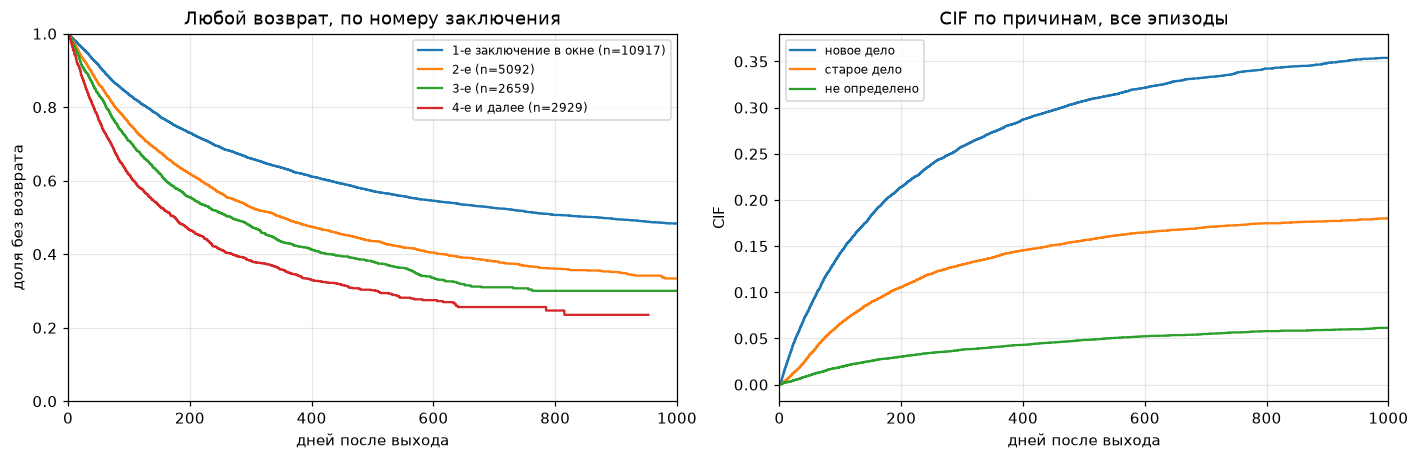

,группа,эпизодов,P(любой возврат ≤ 365),CIF новое дело (365),CIF старое дело (365)
0,1-е заключение в окне,10917,0.372,0.249,0.091
1,2-е,5092,0.509,0.289,0.177
2,3-е,2659,0.572,0.299,0.217
3,4-е и далее,2929,0.652,0.364,0.219


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3)); rows = []
k = ds.k.values
for name, mk in {'1-е заключение в окне': k == 1, '2-е': k == 2, '3-е': k == 3, '4-е и далее': k >= 4}.items():
    tk, sk = sm.km(T[mk], E[mk]); ax[0].step(tk, sk, where='post', label=f'{name} (n={mk.sum()})')
    tg_, aj_, _ = sx.aalen_johansen(T[mk], C[mk])
    rows.append({'группа': name, 'эпизодов': int(mk.sum()), 'P(любой возврат ≤ 365)': 1 - float(sm.km_at(tk, sk, 365)),
                 'CIF новое дело (365)': float(sm.km_at(tg_, aj_[1], 365)), 'CIF старое дело (365)': float(sm.km_at(tg_, aj_[2], 365))})
ax[0].set_xlim(0, 1000); ax[0].set_ylim(0, 1); ax[0].set_ylabel('доля без возврата'); ax[0].set_title('Любой возврат, по номеру заключения')
tg, aj, S_all = sx.aalen_johansen(T, C)
for c in (1, 2, 3): ax[1].step(tg, aj[c], where='post', label=sx.CAUSE_RU[c])
ax[1].set_xlim(0, 1000); ax[1].set_title('CIF по причинам, все эпизоды'); ax[1].set_ylabel('CIF')
for a in ax: a.set_xlabel('дней после выхода'); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('out/km_and_cif.png', dpi=120); plt.show()
pd.DataFrame(rows).round(3)

In [4]:
single = ds.g_cur_n_types.values == 1; rows = []
for s in ['Violent', 'Property', 'Drug', 'Traffic', 'OldCase', 'Unknown']:
    mk = (ds[f'g_cur_{s}'].values == 1) & single; tg_, aj_, _ = sx.aalen_johansen(T[mk], C[mk]); tk, sk = sm.km(T[mk], E[mk])
    rows.append({'состояние узла': s, 'эпизодов': int(mk.sum()), 'P(любой возврат ≤ 365)': 1 - float(sm.km_at(tk, sk, 365)),
                 'CIF новое дело (365)': float(sm.km_at(tg_, aj_[1], 365)), 'CIF старое дело (365)': float(sm.km_at(tg_, aj_[2], 365))})
st = pd.DataFrame(rows); st['доля старых дел'] = st['CIF старое дело (365)'] / (st['CIF новое дело (365)'] + st['CIF старое дело (365)']); st.round(3)

,состояние узла,эпизодов,P(любой возврат ≤ 365),CIF новое дело (365),CIF старое дело (365),доля старых дел
0,Violent,3717,0.277,0.191,0.071,0.270
1,Property,2411,0.553,0.369,0.159,0.302
2,Drug,1923,0.547,0.327,0.189,0.366
3,Traffic,1879,0.416,0.284,0.109,0.277
4,OldCase,3199,0.491,0.212,0.245,0.536
5,Unknown,1989,0.469,0.224,0.051,0.187


### 1.2. Почему для причин нужна CIF, а не 1 − KM

Если считать возврат по новому делу «обычным» событием, а возвраты по старому делу — цензурой, и взять 1 − KM, риск завышается: люди, вернувшиеся по старому делу, как будто остаются под риском нового дела. Разница между пунктирной и сплошной кривой — та ошибка, от которой защищают конкурирующие риски.

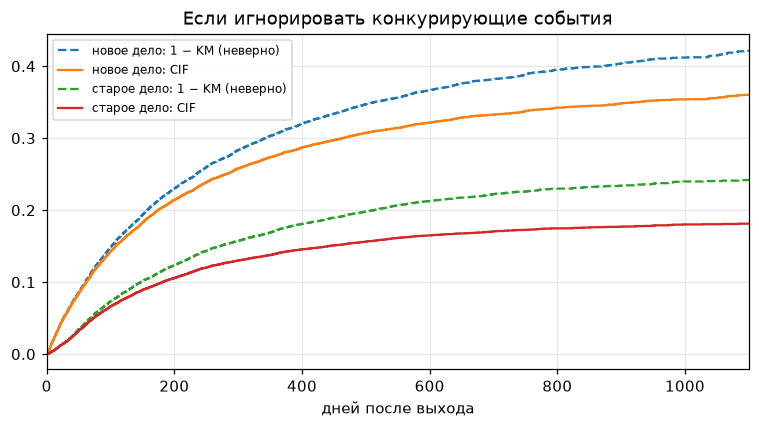

,CIF(180),CIF(365),CIF(730),1 − KM(365)
новое дело,0.204,0.277,0.335,0.308
старое дело,0.100,0.141,0.172,0.174
не определено,0.029,0.041,0.056,0.055


In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for c in (1, 2):
    tk, sk = sm.km(T, (C == c).astype(int)); ax.step(tk, 1 - sk, where='post', ls='--', label=f'{sx.CAUSE_RU[c]}: 1 − KM (неверно)')
    ax.step(tg, aj[c], where='post', label=f'{sx.CAUSE_RU[c]}: CIF')
ax.set_xlim(0, 1100); ax.set_xlabel('дней после выхода'); ax.legend(fontsize=8); ax.grid(alpha=.3); ax.set_title('Если игнорировать конкурирующие события')
plt.tight_layout(); plt.savefig('out/cif_vs_1km.png', dpi=120); plt.show()
rows = {}
for c in (1, 2, 3):
    tk, sk = sm.km(T, (C == c).astype(int))
    rows[sx.CAUSE_RU[c]] = {**{f'CIF({h})': float(sm.km_at(tg, aj[c], h)) for h in (180, 365, 730)}, '1 − KM(365)': 1 - float(sm.km_at(tk, sk, 365))}
pd.DataFrame(rows).T.round(3)

**Что видно.** С номером заключения растут обе причины, но возвраты по старому делу — быстрее (доли за год — в таблице выше). Состояние узла различает причины: после `OldCase` больше половины возвратов — снова по старому делу, после `Violent` риск низкий по обеим причинам, после `Property` выше всего риск нового дела.

## 2. Модель и схема проверки

**Модель — пропорциональные риски Кокса** со шкалой времени «дней с момента выхода».
- Почему Кокс: стандартная интерпретируемая модель для времени до события, она же использовалась в прошлой работе (`cox_model.py`). Для вопроса «что добавляет семейство признаков» важна сравнимость, а не максимальное качество.
- **Для двух причин — причинно-специфические модели Кокса** (cause-specific hazards): для каждой причины своя модель, возвраты по другим причинам — цензура в момент их наступления. Коэффициенты отвечают на вопрос «как признак связан с интенсивностью возврата *этого* типа у тех, кто ещё на свободе». Вероятности (CIF) получаются комбинацией моделей всех причин: F_k(t|x) = Σ_{s ≤ t} S(s−|x) · h_k(s|x). Модель Fine–Gray (прямая модель CIF) не используется: в Python нет готовой реализации, а CIF из причинно-специфических моделей даёт ту же величину.
- Гребневый штраф (`l2 = 0.01`): в полном наборе больше сотни признаков, многие сильно коррелируют. Чувствительность к штрафу — в разделе 5.
- Подготовка признаков: `log1p` для длительностей и счётчиков, для пропусков — индикатор и медиана, затем стандартизация. Всё оценивается только на обучающей части.

**Проверка — 5-кратная кросс-валидация с разбиением по людям.** Эпизоды одного человека зависимы; если они попадут и в обучение, и в тест, качество будет завышено. Поэтому в фолд целиком уходят все эпизоды человека.

**Метрики.**
- *C-индекс Харрелла* — доля пар, где раньше вернувшийся получил более высокий риск (0,5 — случайно, 1 — идеально). Для причины k события других причин считаются цензурой.
- *C Вольберса* — C-индекс для прогноза CIF причины на горизонте 365 дней: человек с конкурирующим событием остаётся в сравнении навсегда (Wolbers et al., 2009).
- *Skill по Брайеру на горизонте t* = 1 − BS(модель) / BS(опорная кривая), с весами IPCW на цензурирование. Опорная кривая — Каплан–Мейер для общего возврата и CIF Аалена–Йохансена для причин. 0 — модель не лучше одной общей кривой.

**Реализация.** Модель и метрики написаны на numpy (`stage2_models.py`, `stage2_extra.py`), чтобы ноутбук считался в любом окружении. Ниже проверка на синтетических данных с известными коэффициентами; сверка с `lifelines` — в разделе 7.

In [6]:
beta_true = np.array([0.8, -0.5, 0.0, 0.3]); B, S, S0 = [], [], []; tt = np.array([0.5, 1.0])
for seed in range(40):                                   # 40 синтетических выборок по 5000 наблюдений
    rng = np.random.default_rng(seed); Xs = rng.normal(size=(5000, 4))
    t_ev = rng.exponential(1 / np.exp(Xs @ beta_true)); t_c = rng.exponential(1.5, 5000)   # ~42% цензурирования
    m = sm.Cox(l2=1e-8).fit(Xs, np.minimum(t_ev, t_c), (t_ev <= t_c).astype(int))
    B.append(m.beta); S.append(m.se); S0.append(m.survival(np.zeros((1, 4)), tt)[0])
B = np.array(B)
display(pd.DataFrame({'истинный коэффициент': beta_true, 'средняя оценка': B.mean(0), 'разброс оценок (SD)': B.std(0, ddof=1), 'средняя SE модели': np.mean(S, 0)}).round(3))
print('базовая выживаемость S0(t) при t = 0.5 и 1.0: средняя оценка', np.mean(S0, 0).round(3), '| истинная', np.exp(-tt).round(3))

базовая выживаемость S0(t) при t = 0.5 и 1.0: средняя оценка [0.605 0.368] | истинная [0.607 0.368]


,истинный коэффициент,средняя оценка,разброс оценок (SD),средняя SE модели
0,0.8,0.803,0.024,0.021
1,-0.5,-0.502,0.022,0.020
2,0.0,-0.000,0.017,0.019
3,0.3,0.301,0.022,0.019


Средние оценки совпадают с истинными коэффициентами, стандартные ошибки — с фактическим разбросом, базовая выживаемость восстанавливается.

**Проверка CIF.** Две причины с постоянными интенсивностями λ₁ = 0,6 и λ₂ = 0,4 без признаков: истинная CIF₁(t) = 0,6 · (1 − e^{−t}). Модели обучаются на синтетике, CIF сравнивается с формулой.

In [7]:
rng = np.random.default_rng(1); n = 20000
t1, t2, tc = rng.exponential(1 / .6, n), rng.exponential(1 / .4, n), rng.exponential(3, n)
tt_ = np.minimum.reduce([t1, t2, tc]); cc = np.select([tt_ == t1, tt_ == t2], [1, 2], 0)
tt_d = np.ceil(tt_ * 100)                                # время в «днях», чтобы сетка была целой
Xz = rng.normal(size=(n, 1)) * 1e-6
ms = [sm.Cox(l2=1e-8).fit(Xz, tt_d, (cc == c).astype(int)) for c in (1, 2)]
grid = np.array([50, 100, 200]); F = sx.cif_from_cox(ms, [Xz[:1]] * 2, np.arange(1, 201))
pd.DataFrame({'t': grid / 100, 'CIF₁ модель': F[0][0, grid - 1], 'CIF₁ истинная': .6 * (1 - np.exp(-grid / 100)),
              'CIF₂ модель': F[1][0, grid - 1], 'CIF₂ истинная': .4 * (1 - np.exp(-grid / 100))}).round(3)

,t,CIF₁ модель,CIF₁ истинная,CIF₂ модель,CIF₂ истинная
0,0.5,0.239,0.236,0.156,0.157
1,1.0,0.381,0.379,0.251,0.253
2,2.0,0.519,0.519,0.348,0.346


## 3. Отдельные признаки

C-индекс каждого признака в одиночку для каждой цели (на случайных 6 000 эпизодах; направление связи не важно, берётся max(C, 1 − C)). Это грубый ориентир: признаки дублируют друг друга.

In [8]:
rs = np.random.default_rng(0).choice(len(ds), 6000, replace=False); rows = []
fam_of = {c: k for k, v in fam.items() for c in v}
for c in fam_of:
    x = ds[c].fillna(ds[c].median()).values[rs]; r = {'признак': c, 'семейство': fam_of[c]}
    for nm, ev in [('любой', E), ('новое', (C == 1).astype(int)), ('старое', (C == 2).astype(int))]:
        ci = sm.c_index(T[rs], ev[rs], x); r[f'C {nm}'] = max(ci, 1 - ci); r[f'знак {nm}'] = '+' if ci > .5 else '−'
    rows.append(r)
uni = pd.DataFrame(rows).sort_values('C любой', ascending=False).reset_index(drop=True); uni.to_csv('out/univariate_c_index.csv', index=False)
display(uni.head(20).round(3))
display(uni.groupby('семейство')[['C любой', 'C новое', 'C старое']].max().round(3).rename(columns=lambda c: c.replace('C', 'макс. C')))

,признак,семейство,C любой,знак любой,C новое,знак новое,C старое,знак старое
0,t_arr_decay_1095,C время,0.636,+,0.652,+,0.649,+
1,h_n_prior_arrests,F типы арестов (вся история),0.630,+,0.643,+,0.627,+
2,h_distinct_types,F типы арестов (вся история),0.626,+,0.638,+,0.625,+
3,t_arr_decay_365,C время,0.626,+,0.638,+,0.652,+
4,t_arr_last_3y,C время,0.624,+,0.635,+,0.646,+
5,c_n_deg_M,F2 обвинения (вся история),0.622,+,0.657,+,0.589,+
6,c_n_cases,F2 обвинения (вся история),0.618,+,0.650,+,0.587,+
7,h_entropy,F типы арестов (вся история),0.613,+,0.625,+,0.608,+
8,c_n_all,F2 обвинения (вся история),0.613,+,0.640,+,0.592,+
9,c_n_Property,F2 обвинения (вся история),0.613,+,0.628,+,0.609,+


,макс. C любой,макс. C новое,макс. C старое
семейство,,,
A база,0.550,0.548,0.564
B RFM,0.583,0.565,0.627
C время,0.636,0.652,0.652
D узел графа,0.550,0.543,0.568
E история по графу,0.579,0.564,0.632
F типы арестов (вся история),0.630,0.643,0.627
F2 обвинения (вся история),0.622,0.657,0.629
G раса,0.546,0.544,0.545


## 4. Вклад семейств признаков

Семейства добавляются по очереди: A база → B RFM → C время → D узел графа → E история по графу → F типы арестов → G раса. Для общего возврата — модель Кокса; для причин — две причинно-специфические модели (плюс модель третьей причины, нужная для CIF).

Прирост к RFM считается **парно**, по тем же фолдам: шум разбиения вычитается.

In [9]:
t = time.time(); names = list(fam); cols = []; CUM = {}; CR = {}
for kname in names:
    cols = cols + fam[kname]
    CUM[kname] = memo(sm.cv_cox, cols)
    if kname != names[0]: CR[kname] = memo(sx.cv_competing, cols)
base = CUM['B RFM'][0]; base_cr = CR['B RFM'][0]
rows = {}
for kname in names:
    r = CUM[kname][0]; row = {'признаков': sum(len(fam[x]) for x in names[:names.index(kname) + 1]),
                              'любой: C': r.c_index.mean(), 'любой: ΔC к RFM': (r.c_index - base.c_index).mean(), 'любой: skill 365': r.skill_365.mean()}
    if kname in CR:
        q = CR[kname][0]
        for c in ['new', 'old']:
            nm = 'новое' if c == 'new' else 'старое'
            row[f'{nm}: C'] = q[f'C_{c}'].mean(); row[f'{nm}: ΔC к RFM'] = (q[f'C_{c}'] - base_cr[f'C_{c}']).mean()
            row[f'{nm}: C Вольберса'] = q[f'Cw_{c}'].mean(); row[f'{nm}: skill 365'] = q[f'skill_{c}_365'].mean()
    rows[('' if kname == names[0] else '+ ') + kname] = row
abl = pd.DataFrame(rows).T; abl.to_csv('out/ablation_by_cause.csv')
print(f'время расчёта {time.time() - t:.0f} с (из кэша — около 0)')
abl.round(4)

время расчёта 130 с (из кэша — около 0)


,признаков,любой: C,любой: ΔC к RFM,любой: skill 365,новое: C,новое: ΔC к RFM,новое: C Вольберса,новое: skill 365,старое: C,старое: ΔC к RFM,старое: C Вольберса,старое: skill 365
A база,2.0,0.5588,-0.0869,0.0241,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
+ B RFM,8.0,0.6457,0.0000,0.1340,0.6598,0.0000,0.6422,0.0717,0.6718,0.0000,0.6279,0.0458
+ C время,25.0,0.6645,0.0188,0.1584,0.6895,0.0297,0.6721,0.1065,0.6851,0.0133,0.6456,0.0545
+ D узел графа,61.0,0.6769,0.0312,0.1780,0.7111,0.0513,0.6955,0.1350,0.7065,0.0347,0.6803,0.0728
+ E история по графу,89.0,0.6808,0.0351,0.1813,0.7139,0.0541,0.6986,0.1390,0.7094,0.0376,0.6845,0.0754
+ F типы арестов (вся история),105.0,0.6819,0.0363,0.1825,0.7153,0.0555,0.6999,0.1407,0.7088,0.0370,0.6838,0.0744
+ F2 обвинения (вся история),126.0,0.6864,0.0407,0.1891,0.7278,0.0680,0.7132,0.1605,0.7091,0.0373,0.6872,0.0760
+ G раса,129.0,0.6868,0.0411,0.1900,0.7278,0.0680,0.7132,0.1606,0.7100,0.0382,0.6883,0.0767


In [10]:
full, full_cr = CUM['G раса'][0], CR['G раса'][0]
pd.DataFrame({nm: {'C: RFM': base[col].mean() if c is None else base_cr[col].mean(),
                   'C: все семейства': full[col].mean() if c is None else full_cr[col].mean(),
                   'ΔC (парно)': ((full[col] - base[col]) if c is None else (full_cr[col] - base_cr[col])).mean(),
                   'sd ΔC': ((full[col] - base[col]) if c is None else (full_cr[col] - base_cr[col])).std(ddof=1),
                   'мин. ΔC по фолдам': ((full[col] - base[col]) if c is None else (full_cr[col] - base_cr[col])).min()}
              for nm, col, c in [('любой возврат', 'c_index', None), ('новое дело', 'C_new', 1), ('старое дело', 'C_old', 2)]}).T.round(4)

,C: RFM,C: все семейства,ΔC (парно),sd ΔC,мин. ΔC по фолдам
любой возврат,0.6457,0.6868,0.0411,0.0028,0.0378
новое дело,0.6598,0.7278,0.0680,0.0023,0.0652
старое дело,0.6718,0.7100,0.0382,0.0061,0.0285


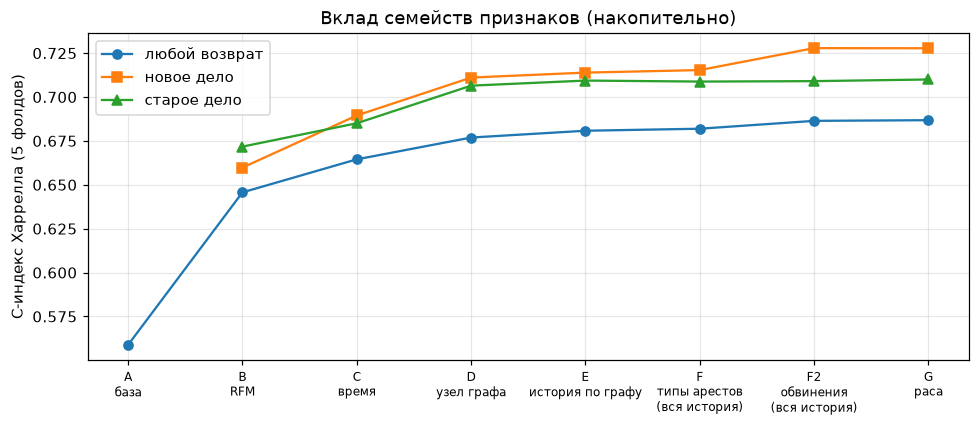

In [11]:
fig, ax = plt.subplots(figsize=(9, 4)); x = range(len(names))
ax.plot(x, [CUM[k][0].c_index.mean() for k in names], 'o-', label='любой возврат')
ax.plot(x[1:], [CR[k][0].C_new.mean() for k in names[1:]], 's-', label='новое дело')
ax.plot(x[1:], [CR[k][0].C_old.mean() for k in names[1:]], '^-', label='старое дело')
ax.set_xticks(list(x)); ax.set_xticklabels([k.replace(' ', '\n', 1).replace(' (', '\n(') for k in names], fontsize=8)
ax.set_ylabel('C-индекс Харрелла (5 фолдов)'); ax.grid(alpha=.3); ax.legend(); ax.set_title('Вклад семейств признаков (накопительно)')
plt.tight_layout(); plt.savefig('out/ablation.png', dpi=120); plt.show()

### 4.1. Что каждое семейство добавляет к RFM само по себе

Не зависит от порядка добавления. Только общий возврат и новое / старое дело по C Харрелла.

In [12]:
rows = {}
for kname in names[2:]:
    r, _ = memo(sm.cv_cox, RFM + fam[kname]); q, _ = memo(sx.cv_competing, RFM + fam[kname])
    rows['RFM + ' + kname] = {'любой: ΔC': (r.c_index - base.c_index).mean(), 'новое: ΔC': (q.C_new - base_cr.C_new).mean(), 'старое: ΔC': (q.C_old - base_cr.C_old).mean()}
plus = pd.DataFrame(rows).T.round(4); plus.to_csv('out/ablation_rfm_plus_one.csv'); plus

,любой: ΔC,новое: ΔC,старое: ΔC
RFM + C время,0.0188,0.0297,0.0133
RFM + D узел графа,0.0180,0.0330,0.0298
RFM + E история по графу,0.0097,0.0187,0.0098
RFM + F типы арестов (вся история),0.0193,0.0338,0.0054
RFM + F2 обвинения (вся история),0.0271,0.0518,0.0151
RFM + G раса,0.0015,0.0007,0.0011


## 5. Проверки устойчивости (общий возврат)

In [13]:
def cv_sub(d, cols): return sm.cv_cox(d, cols, subsets={'k1': d.k.values == 1, 'k2plus': d.k.values >= 2})
cv_sub.__module__ = 'nb02'; rows = {}
for name, cset in {'RFM': RFM, 'все семейства': ALL}.items():
    r, _ = memo(cv_sub, cset)
    rows[name] = {'все эпизоды': r.c_index.mean(), 'первый эпизод (k = 1)': r.c_k1.mean(), 'повторные (k ≥ 2)': r.c_k2plus.mean()}
first = ds[ds.k == 1].reset_index(drop=True)
rows['все семейства, обучение только на первых эпизодах'] = {'первый эпизод (k = 1)': sx.make_memo(first, USE_CACHE)(sm.cv_cox, ALL)[0].c_index.mean()}
pd.DataFrame(rows).T.round(4)

,все эпизоды,первый эпизод (k = 1),повторные (k ≥ 2)
RFM,0.6457,0.6569,0.5968
все семейства,0.6868,0.6937,0.6494
"все семейства, обучение только на первых эпизодах",NaN,0.6969,NaN


Сила штрафа (полный набор, общий возврат):

In [14]:
pd.DataFrame({l2: memo(sm.cv_cox, ALL, l2=l2)[0][['c_index', 'skill_365']].mean() for l2 in [1e-3, 1e-2, 1e-1, 1.0]}).T.round(4).rename_axis('l2')

,c_index,skill_365
l2,,
0.001,0.6869,0.1897
0.010,0.6868,0.1900
0.100,0.6865,0.1900
1.000,0.6824,0.1826


### 5.1. Сравнение с арестом как событием
Та же модель (RFM и все семейства) для ареста как события: любой арест и арест по новому уголовному делу (цели считаются в ноутбуке 01, как в папке `этап2_выбор_события`).

In [15]:
rows = {}
for tgt in ['custody', 'arrest', 'newarrest']:
    a, _ = memo(sm.cv_cox, RFM, target=tgt); b, _ = memo(sm.cv_cox, ALL, target=tgt)
    rows[tgt] = {'доля событий': ds[f'event_{tgt}'].mean(), 'C: RFM': a.c_index.mean(), 'C: все': b.c_index.mean(), 'ΔC': (b.c_index - a.c_index).mean()}
pd.DataFrame(rows).T.round(3).rename(index={'custody': 'вход в заключение', 'arrest': 'любой арест', 'newarrest': 'арест по новому делу'})

,доля событий,C: RFM,C: все,ΔC
вход в заключение,0.523,0.646,0.687,0.041
любой арест,0.526,0.665,0.701,0.036
арест по новому делу,0.328,0.659,0.725,0.066


## 6. Итоговые модели

### 6.1. Коэффициенты: общий возврат и две причины

Три модели на всех данных с полным набором признаков. HR — отношение рисков на одно стандартное отклонение признака (после `log1p`, где он применялся); для расы HR пересчитан на индикатор (группа против Caucasian). `z разницы` = (β_new − β_old) / √(SE_new² + SE_old²) — насколько признак по-разному связан с двумя причинами. SE наивные, без поправки на повторные эпизоды одного человека; **основная таблица значимости — раздел 7** (lifelines, SE кластеризованы по человеку). Здесь смотреть стоит на порядок величины. Из-за корреляции признаков знак отдельного коэффициента нельзя читать как причинное влияние.

In [16]:
prep = sm.Prep().fit(ds, ALL); Xall = prep.transform(ds)
cox = sm.Cox(l2=0.01).fit(Xall, T, E)
mods = {c: sm.Cox(l2=0.01).fit(Xall, T, (C == c).astype(int)) for c in (1, 2, 3)}
fam_of2 = lambda c: fam_of.get(c[:-3] if c.endswith('_na') else c, '')
coef = pd.DataFrame({'признак': prep.keep, 'семейство': [fam_of2(c) for c in prep.keep],
                     'HR любой': np.exp(cox.beta), 'z любой': cox.beta / cox.se,
                     'HR новое': np.exp(mods[1].beta), 'z новое': mods[1].beta / mods[1].se,
                     'HR старое': np.exp(mods[2].beta), 'z старое': mods[2].beta / mods[2].se})
coef['z разницы'] = (mods[1].beta - mods[2].beta) / np.sqrt(mods[1].se ** 2 + mods[2].se ** 2)
coef.to_csv('out/cox_coefficients_by_cause.csv', index=False)
coef.reindex(coef[['z любой', 'z новое', 'z старое']].abs().max(axis=1).sort_values(ascending=False).index).head(20).round(3).reset_index(drop=True)

,признак,семейство,HR любой,z любой,HR новое,z новое,HR старое,z старое,z разницы
0,c_n_cases,F2 обвинения (вся история),1.248,4.661,1.812,9.605,0.797,-2.593,7.664
1,g_cur_start_state,D узел графа,1.086,7.484,1.060,4.579,0.946,-0.418,0.852
2,a_age,A база,0.778,-7.382,0.777,-5.146,0.800,-3.042,-0.341
3,c_n_1y,F2 обвинения (вся история),1.118,5.475,1.221,7.262,0.977,-0.666,5.041
4,r_days_since_prev_arrest,B RFM,0.901,-5.478,0.933,-2.832,0.764,-6.963,4.363
5,gh_n_felony_prev,E история по графу,0.919,-4.475,0.852,-6.696,1.052,1.410,-4.872
6,g_cur_prison,D узел графа,0.943,-3.911,1.017,0.938,0.771,-5.737,5.680
7,gh_n_Violent,E история по графу,0.916,-5.271,0.908,-4.483,0.934,-2.244,-0.769
8,h_n_PublicOrder,F типы арестов (вся история),0.930,-3.598,0.887,-4.846,1.011,0.289,-2.841
9,c_n_noarrest_cases,F2 обвинения (вся история),0.907,-2.312,0.783,-4.558,1.180,2.117,-4.321


Признаки, сильнее всего различающие причины (по |z разницы|):

In [17]:
coef.reindex(coef['z разницы'].abs().sort_values(ascending=False).index).head(10).round(3).reset_index(drop=True)

,признак,семейство,HR любой,z любой,HR новое,z новое,HR старое,z старое,z разницы
0,c_n_cases,F2 обвинения (вся история),1.248,4.661,1.812,9.605,0.797,-2.593,7.664
1,g_cur_prison,D узел графа,0.943,-3.911,1.017,0.938,0.771,-5.737,5.680
2,c_n_1y,F2 обвинения (вся история),1.118,5.475,1.221,7.262,0.977,-0.666,5.041
3,gh_n_felony_prev,E история по графу,0.919,-4.475,0.852,-6.696,1.052,1.410,-4.872
4,r_days_since_prev_arrest,B RFM,0.901,-5.478,0.933,-2.832,0.764,-6.963,4.363
5,c_n_all,F2 обвинения (вся история),0.939,-1.213,0.754,-4.111,1.260,2.399,-4.339
6,c_n_noarrest_cases,F2 обвинения (вся история),0.907,-2.312,0.783,-4.558,1.180,2.117,-4.321
7,g_cur_deg_F1,D узел графа,0.975,-1.175,0.912,-3.164,1.077,1.937,-3.457
8,gh_prev_cause_unknown,E история по графу,1.016,0.387,0.945,-1.044,1.376,3.329,-3.410
9,g_cur_deg_MO3,D узел графа,1.017,1.064,1.049,2.380,0.911,-2.572,3.403


Сильнейшие признаки каждой причины (по |z|):

In [18]:
top = pd.concat([coef.reindex(coef['z новое'].abs().sort_values(ascending=False).index).head(10)[['признак', 'HR новое', 'z новое']].reset_index(drop=True),
                 coef.reindex(coef['z старое'].abs().sort_values(ascending=False).index).head(10)[['признак', 'HR старое', 'z старое']].reset_index(drop=True)], axis=1)
top.round(3)

,признак,HR новое,z новое,признак,HR старое,z старое
0,c_n_cases,1.812,9.605,r_days_since_prev_arrest,0.764,-6.963
1,c_n_1y,1.221,7.262,g_cur_prison,0.771,-5.737
2,gh_n_felony_prev,0.852,-6.696,t_age_first_arrest_na,0.683,-3.646
3,a_age,0.777,-5.146,t_iai_last,1.144,3.383
4,h_n_PublicOrder,0.887,-4.846,race_Other,0.931,-3.337
5,g_cur_start_state,1.060,4.579,gh_prev_cause_unknown,1.376,3.329
6,c_n_noarrest_cases,0.783,-4.558,a_age,0.800,-3.042
7,gh_n_Violent,0.908,-4.483,h_n_Violent,1.138,2.968
8,c_n_deg_M,1.191,4.269,race_Hispanic,0.944,-2.849
9,c_n_all,0.754,-4.111,c_n_Violent,0.875,-2.784


#### Пример: прогноз для трёх типичных эпизодов

Для эпизодов каждого типа (узел с одним типом) — медиана CIF по причинам из итоговых моделей: как по-разному выглядит риск после первого заключения за Violent, второго за Drug и третьего и далее за OldCase.

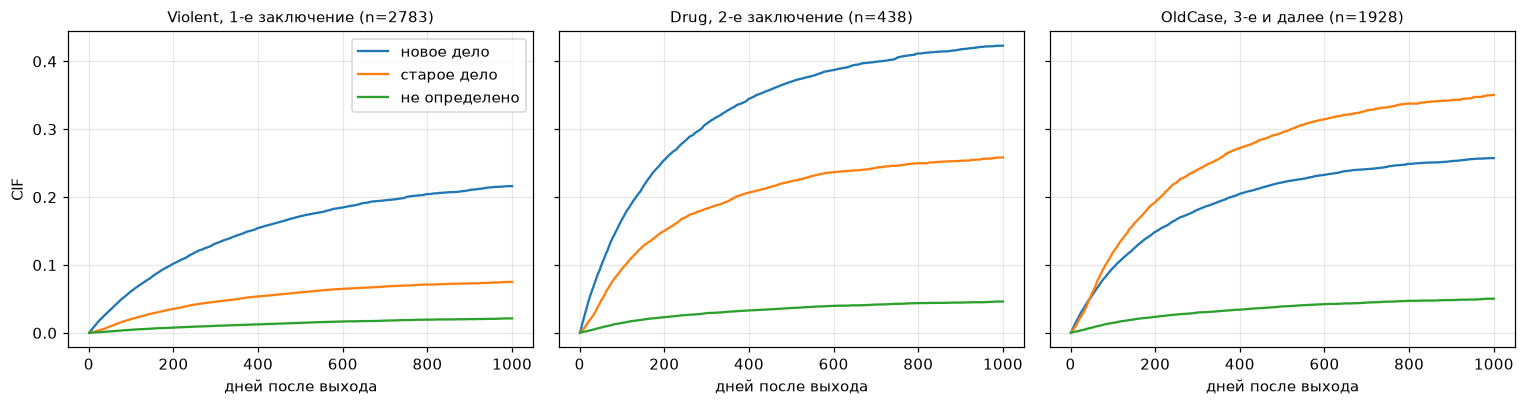

,эпизод,новое дело: медиана CIF(365),старое дело: медиана CIF(365),не определено: медиана CIF(365)
0,"Violent, 1-е заключение",0.147,0.051,0.012
1,"Drug, 2-е заключение",0.333,0.199,0.032
2,"OldCase, 3-е и далее",0.197,0.263,0.033


In [19]:
grid = np.arange(1, 1001)
cases = {'Violent, 1-е заключение': (ds.g_cur_Violent == 1) & single & (ds.k == 1),
         'Drug, 2-е заключение': (ds.g_cur_Drug == 1) & single & (ds.k == 2),
         'OldCase, 3-е и далее': (ds.g_cur_OldCase == 1) & single & (ds.k >= 3)}
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True); rows = []
for ax, (name, mk_) in zip(axs, cases.items()):
    Xi = Xall[mk_.values]; F = sx.cif_from_cox([mods[1], mods[2], mods[3]], [Xi] * 3, grid)
    for c, f in zip((1, 2, 3), F): ax.plot(grid, np.median(f, axis=0), label=sx.CAUSE_RU[c])
    ax.set_title(f'{name} (n={mk_.sum()})', fontsize=10); ax.grid(alpha=.3); ax.set_xlabel('дней после выхода')
    rows.append({'эпизод': name, **{f'{sx.CAUSE_RU[c]}: медиана CIF(365)': np.median(f[:, 364]) for c, f in zip((1, 2, 3), F)}})
axs[0].set_ylabel('CIF'); axs[0].legend(); plt.tight_layout(); plt.savefig('out/competing_examples.png', dpi=120); plt.show()
pd.DataFrame(rows).round(3)

In [20]:
rows = []
for lv in sx.RACE_LEVELS:
    c = f'race_{lv}'; j = prep.keep.index(c); r = {'группа (к Caucasian)': lv}
    for nm, m in [('любой', cox), ('новое', mods[1]), ('старое', mods[2])]:
        b, se = m.beta[j] / prep.sd[c], m.se[j] / prep.sd[c]
        r[f'HR {nm}'] = np.exp(b); r[f'95% {nm}'] = f'{np.exp(b - 1.96 * se):.2f}–{np.exp(b + 1.96 * se):.2f}'
    rows.append(r)
print('Раса в итоговых моделях (с учётом всех остальных признаков):')
pd.DataFrame(rows).round(3)

Раса в итоговых моделях (с учётом всех остальных признаков):


,группа (к Caucasian),HR любой,95% любой,HR новое,95% новое,HR старое,95% старое
0,AfricanAmerican,1.016,0.97–1.06,1.019,0.96–1.08,0.987,0.91–1.07
1,Hispanic,0.822,0.75–0.89,0.843,0.75–0.94,0.801,0.69–0.93
2,Other,0.856,0.78–0.94,0.930,0.82–1.05,0.731,0.61–0.88


### 6.2. Калибровка на горизонте 1 год

Прогнозы вне обучения (out-of-fold) делятся на 10 групп по предсказанной вероятности; фактическая доля в группе — Каплан–Мейер для общего возврата и Аален–Йохансен для причин.

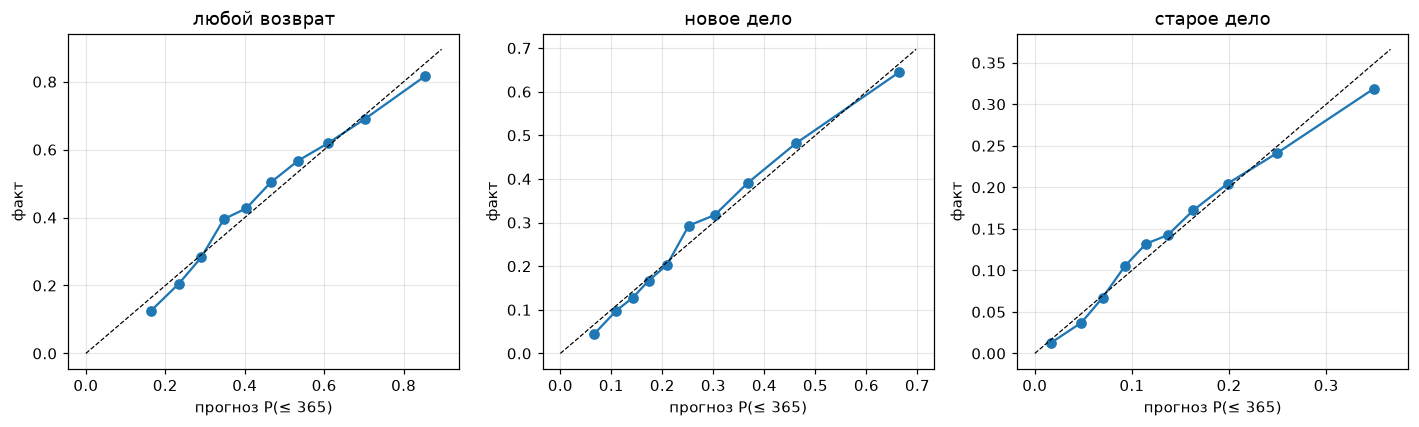

,группа 1,группа 2,группа 3,группа 4,группа 5,группа 6,группа 7,группа 8,группа 9,группа 10,макс |факт − прогноз|
любой возврат,-0.038,-0.029,-0.008,0.048,0.023,0.038,0.033,0.009,-0.012,-0.037,0.048
новое дело,-0.022,-0.012,-0.014,-0.006,-0.006,0.041,0.015,0.024,0.020,-0.019,0.041
старое дело,-0.004,-0.011,-0.003,0.012,0.018,0.006,0.009,0.006,-0.008,-0.030,0.030


In [21]:
oof_any = 1 - CUM['G раса'][1]; oof_c = full_cr_oof = CR['G раса'][1]
fig, axs = plt.subplots(1, 3, figsize=(13, 4)); rows = {}
for ax, (nm, p, c) in zip(axs, [('любой возврат', oof_any, None), ('новое дело', oof_c[1], 1), ('старое дело', oof_c[2], 2)]):
    dec = pd.qcut(p, 10, labels=False); pr, fa = [], []
    for d in range(10):
        mk = dec == d; pr.append(p[mk].mean())
        if c is None: tk, sk = sm.km(T[mk], E[mk]); fa.append(1 - float(sm.km_at(tk, sk, 365)))
        else: tg_, aj_, _ = sx.aalen_johansen(T[mk], C[mk]); fa.append(float(sm.km_at(tg_, aj_[c], 365)))
    ax.plot(pr, fa, 'o-'); mx = max(max(pr), max(fa)) * 1.05; ax.plot([0, mx], [0, mx], 'k--', lw=.8)
    ax.set_title(nm); ax.set_xlabel('прогноз P(≤ 365)'); ax.set_ylabel('факт'); ax.grid(alpha=.3)
    rows[nm] = np.array(fa) - np.array(pr)
plt.tight_layout(); plt.savefig('out/calibration_365.png', dpi=120); plt.show()
cal = pd.DataFrame(rows, index=[f'группа {d + 1}' for d in range(10)]).T.round(3); cal['макс |факт − прогноз|'] = cal.abs().max(axis=1); cal.to_csv('out/calibration_365.csv'); cal

### 6.3. Калибровка по расе: зачем раса в модели

Средний прогноз вероятности возврата за год и фактическая доля по группам — для модели без расы (семейства A–F2) и с расой. Отношение прогноз / факт около 1 означает, что модель не завышает и не занижает риск группы.

In [22]:
oof_norace = 1 - CUM[names[-2]][1]; oof_cr_norace = CR[names[-2]][1]; rows = []
for g in ['AfricanAmerican', 'Caucasian', 'Hispanic', 'Other']:
    mk = ds.race4.values == g; tk, sk = sm.km(T[mk], E[mk]); tg_, aj_, _ = sx.aalen_johansen(T[mk], C[mk])
    fact = {'любой': 1 - float(sm.km_at(tk, sk, 365)), 'новое': float(sm.km_at(tg_, aj_[1], 365)), 'старое': float(sm.km_at(tg_, aj_[2], 365))}
    r = {'группа': g, 'эпизодов': int(mk.sum())}
    for nm, p0, p1 in [('любой', oof_norace, oof_any), ('новое', oof_cr_norace[1], oof_c[1]), ('старое', oof_cr_norace[2], oof_c[2])]:
        r[f'{nm}: прогноз/факт без расы'] = p0[mk].mean() / fact[nm]; r[f'{nm}: прогноз/факт с расой'] = p1[mk].mean() / fact[nm]
    r['C внутри группы (любой, с расой)'] = sm.c_index(T[mk], E[mk], oof_any[mk])
    rows.append(r)
race_cal = pd.DataFrame(rows).round(3); race_cal.to_csv('out/race_calibration.csv', index=False); race_cal

,группа,эпизодов,любой: прогноз/факт без расы,любой: прогноз/факт с расой,новое: прогноз/факт без расы,новое: прогноз/факт с расой,старое: прогноз/факт без расы,старое: прогноз/факт с расой,"C внутри группы (любой, с расой)"
0,AfricanAmerican,11686,0.984,0.998,0.976,0.987,1.002,1.014,0.669
1,Caucasian,7155,0.987,0.996,0.983,0.986,0.991,1.022,0.686
2,Hispanic,1586,1.152,1.011,1.096,0.979,1.205,1.058,0.707
3,Other,1170,1.152,1.041,1.085,1.052,1.319,1.045,0.724


### 6.4. Метрики как у Коледы: IBS и AUPRC (библиотека survivors)

Те же функции, что в `DKoleda6/recurrent_event` (`metrics/ibs.py`, `metrics/auprc.py`): `survivors.metrics.ibs_remain` и `survivors.metrics.auprc`. Сетка — 200 точек от 0 до 95 %-квантиля длительностей эпизодов train, как у Коледы. Цель — любой возврат (у Коледы один тип события), 5 фолдов по людям. IBS — чем меньше, тем лучше; AUPRC — чем больше, тем лучше. С числами Коледы напрямую не сравнимо: другая шкала времени (у неё накопленная, от входа), данные и признаки. Если `survivors` не установлен (`pip install survivors`), ячейка пропускается.

In [23]:
try:
    rows = {}
    for name, cset in {'RFM': RFM, 'все семейства': ALL}.items():
        r = memo(sm.cv_survivors, cset)
        rows[name] = {'IBS': r.IBS.mean(), 'sd IBS': r.IBS.std(ddof=1), 'AUPRC': r.AUPRC.mean(), 'sd AUPRC': r.AUPRC.std(ddof=1), 'горизонт сетки, дн.': r.horizon.mean()}
    kol = pd.DataFrame(rows).T.round(4); kol.to_csv('out/koleda_metrics.csv'); display(kol)
except ImportError:
    print('survivors не установлен в этом окружении (pip install survivors) — ячейка пропущена')
except Exception as e:                                   # ошибка внутри survivors не должна останавливать ноутбук
    print('survivors: ошибка при расчёте —', type(e).__name__, e)

,IBS,sd IBS,AUPRC,sd AUPRC,"горизонт сетки, дн."
RFM,0.1849,0.0024,0.4555,0.0029,1069.4
все семейства,0.1741,0.0036,0.4778,0.0027,1069.4


## 7. Перепроверка в lifelines и нелинейная модель 

- **lifelines**: те же модели Кокса (общий возврат и две причины) со стандартными ошибками, кластеризованными по человеку, и сверка коэффициентов с numpy-реализацией.
- **Random Survival Forest**: не теряет ли линейная модель взаимодействия между признаками. Для причин лес строится отдельно для каждой причины (другие причины — цензура), C Харрелла.

In [24]:
try:
    from lifelines import CoxPHFitter
    out = {}
    for nm, ev, m in [('любой', E, cox), ('новое', (C == 1).astype(int), mods[1]), ('старое', (C == 2).astype(int), mods[2])]:
        Z = pd.DataFrame(Xall, columns=prep.keep); Z['time'] = T; Z['event'] = ev; Z['person_id'] = ds.person_id.values
        cph = CoxPHFitter(penalizer=0.01).fit(Z, 'time', 'event', cluster_col='person_id')
        sumr = cph.summary[['coef', 'exp(coef)', 'se(coef)', 'z', 'p']]; sumr.to_csv(f'out/cox_lifelines_cluster_{nm}.csv')
        print(nm, '— корреляция коэффициентов numpy и lifelines:', round(np.corrcoef(m.beta, sumr.loc[prep.keep, 'coef'].values)[0, 1], 4))
        out[nm] = sumr['z']
    display(pd.DataFrame(out).reindex(pd.DataFrame(out).abs().max(axis=1).sort_values(ascending=False).index).head(25).round(2))
except ImportError:
    print('lifelines не установлен в этом окружении — ячейка пропущена')

любой — корреляция коэффициентов numpy и lifelines: 0.9855
новое — корреляция коэффициентов numpy и lifelines: 0.9453
старое — корреляция коэффициентов numpy и lifelines: 0.9208


,любой,новое,старое
covariate,,,
t_age_first_arrest_na,2.82,-2.44,-19.94
g_cur_deg_M2,7.75,11.58,-1.21
gh_prev_cause_unknown,1.16,-3.00,11.29
gh_prev_cause_new,-1.77,3.05,-11.12
c_n_cases,5.65,11.11,-2.05
g_cur_deg_F3,-1.79,-5.70,9.64
g_cur_reason_unlinked,-0.22,1.36,-9.25
g_cur_start_state,8.80,5.51,-6.96
a_age,-7.99,-8.59,-5.64


In [25]:
RUN_RSF = True    # пересчитать лес на сборке 18.11 (~6 мин); False - показать сохранённый out/rsf_vs_cox.csv
try:
    if not RUN_RSF: raise ImportError
    from sksurv.ensemble import RandomSurvivalForest
    from sksurv.util import Surv
    folds = sm.person_folds(ds.person_id.values); rows = []; t = time.time()
    for target, ev in [('любой', E), ('новое', (C == 1).astype(int)), ('старое', (C == 2).astype(int))]:
        for name, cset in {'RFM': RFM, 'все семейства': ALL}.items():
            cs = []
            for f in range(5):
                tr, te = folds != f, folds == f; pp = sm.Prep().fit(ds[tr], cset)
                rsf = RandomSurvivalForest(n_estimators=100, min_samples_leaf=50, max_features='sqrt', max_samples=0.5, n_jobs=-1, random_state=0)
                rsf.fit(pp.transform(ds[tr]), Surv.from_arrays(ev[tr].astype(bool), T[tr]))
                cs.append(sm.c_index(T[te], ev[te], rsf.predict(pp.transform(ds[te]))))
            rows.append({'цель': target, 'набор': name, 'RSF: C': np.mean(cs), 'sd': np.std(cs, ddof=1)})
    rsf_tbl = pd.DataFrame(rows).round(3); rsf_tbl.to_csv('out/rsf_vs_cox.csv', index=False); print(f'время {time.time() - t:.0f} с'); display(rsf_tbl)
except ImportError:
    import os
    if not RUN_RSF and os.path.exists('out/rsf_vs_cox.csv'):
        print('RUN_RSF = False — показан сохранённый результат out/rsf_vs_cox.csv'); display(pd.read_csv('out/rsf_vs_cox.csv'))
    else:
        print('scikit-survival не установлен в этом окружении (или RUN_RSF = False) — ячейка пропущена')

время 387 с


,цель,набор,RSF: C,sd
0,любой,RFM,0.655,0.008
1,любой,все семейства,0.680,0.007
2,новое,RFM,0.668,0.010
3,новое,все семейства,0.710,0.010
4,старое,RFM,0.682,0.004
5,старое,все семейства,0.713,0.005


In [26]:
print(f'время всего ноутбука: {time.time() - t_start:.0f} с')

время всего ноутбука: 1466 с


## Выводы

**Данные (сборка 18.11).** 21 597 эпизодов на свободе у 10 917 человек; возвратом в заключение заканчиваются 52,3%: по новому делу 31,3%, по старому 15,9%, причина не определена у 5,2%. За год (CIF): новое дело 27,7%, старое 14,1%.

**Вклад семейств (C-индекс, кросс-валидация по людям).**

| | RFM | все семейства (129 признаков) | ΔC |
|---|---|---|---|
| любой возврат | 0,646 | 0,687 | +0,041 |
| новое дело | 0,660 | 0,728 | +0,068 |
| старое дело | 0,672 | 0,710 | +0,038 |

- По отдельности к RFM больше всего добавляют обвинения F2 (+0,027; для нового дела +0,052), типы арестов F (+0,019; новое +0,034), время C (+0,019) и текущий узел графа D (+0,018; новое +0,033, старое +0,030); история по графу E — +0,010; раса G — +0,0015.
- Для старого дела главный источник прироста — текущий узел графа (+0,030; F и F2 дают +0,005 и +0,015). По сравнению со сборкой 17.11 вклад узла для старого дела вырос (+0,022 → +0,030): старое дело теперь определяется по прошлому заключению по делу, а это и есть информация графа.
- Возврат по старому делу медленнее после prison (HR 0,77) и тем быстрее, чем ближе к выходу был последний арест (HR 0,76 на ст. откл.); число дел в истории ускоряет новое дело (HR 1,81) и не ускоряет старое (0,80).
- На повторных эпизодах (k ≥ 2) качество ниже: 0,649 против 0,694 на первых.
- Для сравнения, та же модель для ареста как события: любой арест 0,665 → 0,701, арест по новому делу 0,659 → 0,725.
- Коэффициенты lifelines совпадают с моделью на numpy (корреляция 0,92–0,99). RSF не лучше Кокса: 0,680 / 0,710 / 0,713 против 0,687 / 0,728 / 0,710.
- Калибровка за год: отклонение факта от прогноза не больше 4,8 п. п. по децилям риска. IBS 0,174 против 0,185 у RFM, AUPRC 0,478 против 0,456.

